# Охват рекламы в Яндекс Лавке


**Автор:** Долгополова Анна  
**Группа:** БПМ244 (ПМ-14)

На семинаре заполните разделы 1–3 и начните работу с данными. Дома завершите расчёты, выводы и ограничения. Добавляйте ячейки по мере необходимости.

[ТЗ](assignment.md) · [Описание данных](README.md)

Распакуйте архив целиком и сохраняйте ноутбук рядом с тремя CSV и папкой `images`.

## 1. Бизнес-контекст

Зачем бизнесу нужны эти данные?


В Яндекс Лавке реклама может быть размещена в разных местах: на главной в ленте и в поиске. Потенциальная аудитория приложения по-разному взаимодействует с разделами приложения и пролистывает ленту на разную глубину.

Рекламной команде необходимо планировать продажи рекламных размещений до конца 2026 года, для чего и важно знать потенциальный охват рекламных мест.

В рамках исследования необходимо оценить среднедневное количество уникальных пользователей, которые потенциально увидят каждый из выбранных рекламных баннеров, при условии, что реклама доступна всем пользователям без ограничений.

Оценка необходима для пяти рекламных мест: 4 баннера в ленте и один большой на первом экране страницы поиска.

Расчёт необходимо выполнить отдельно для октября, ноября и декабря 2026 года.

## 2. Исследовательский вопрос

Зафиксируйте вопрос, на который вы хотите ответить в рамках этого исследования?


**Какой среднедневной охват (число уникальных пользователей в день, которые увидят баннер) может обеспечить каждое из 5 рекламных мест в октябре, ноябре и декабре 2026 года, если реклама показывается всем пользователям без таргетинга?**

Места:
- 4 баннера в ленте: «Сырная шпаргалка», Monterra, «Выбираем манго с „Артфрут“» и «Идеи»
- большой баннер на первом экране поиска (сейчас там Циан)

Оцениваем само место, а не бренд, который там сейчас стоит.

## 3. Методология

Сначала опишите, каким способом вы ответите на исследовательский вопрос (краткое описание общей логики). Затем уточните детали: какие данные вы будете использовать, и как будете их преобразовывать/агрегировать. Описание должно быть достаточно подробным, чтобы другой аналитик мог воспроизвести ваш подход.



Для оценки охвата используем данные о поведении пользователей с 1 по 28 сентября и прогноз среднего DAU на октябрь–декабрь 2026 года.

Общая идея: охват места = DAU × доля активных за день пользователей, которые видят это место. Доли считаем по сентябрю, DAU берём из плана на нужный месяц.

Для рекламных мест в ленте определим
1. какую долю пользователей составляет аудитория ленты
2. какая доля пользователей ленты доходит до каждого рекламного места.

После для каждого места умножим прогнозный DAU на эти доли.

Для баннера на странице поиска определим долю пользователей, которые открывают поиск (тк он находится на первом экране).

Детали:
- активный пользователь дня — тот, у кого в этот день есть `app_open`. DAU = число таких уникальных пользователей за день
- аудитория ленты / поиска за день — уникальные пользователи с `section_open` в `feed` / `search`
- баннеры в ленте по схеме стоят в рядах 3, 6, 12 и 15. Ленту листают сверху вниз, поэтому пользователь увидел баннер в ряду r, если самый дальний ряд, который ему показали за день, ≥ r
- доля = средний дневной охват места / средний DAU за 28 дней
- итог: доля × план DAU на октябрь, ноябрь и декабрь

Показатели рассчитываем по действиям пользователей из `navigation_events.csv` и `product_impressions.csv`, прогноз DAU берём из `dau_forecast.csv`.

## 4. Подготовка данных и реализация расчётов

### 4.1. Загрузка и знакомство с данными

Загрузите три таблицы и изучите их структуру и содержимое.

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")

In [2]:
dau = pd.read_csv('dau_forecast.csv')
navigation = pd.read_csv('navigation_events.csv')
impressions = pd.read_csv('product_impressions.csv')

In [3]:
display(dau.head())
print()
print()

display(navigation.head())
print()
print()

display(impressions.head())

,month,avg_dau_plan,avg_dau_actual
0,2026-01,"820,00","811,35"
1,2026-02,"840,00","853,18"
2,2026-03,"875,00","864,52"
3,2026-04,"900,00","913,70"
4,2026-05,"930,00","921,16"


,user_id,timestamp,event_type,section
0,u02703,01.09.2026 07:00:19,app_open,NaN
1,u04000,01.09.2026 07:00:19,app_open,NaN
2,u04000,01.09.2026 07:00:22,section_open,feed
3,u02703,01.09.2026 07:00:29,section_open,search
4,u02703,01.09.2026 07:00:50,section_open,search


,user_id,timestamp,section,product_id,row_number,column
0,u04000,2026-09-01 07:00:24,feed,p0775,"1,0",left
1,u04000,2026-09-01 07:00:24,feed,p0842,"1,0",right
2,u04000,2026-09-01 07:00:28,feed,p1782,"2,0",left
3,u04000,2026-09-01 07:00:28,feed,p1788,"2,0",right
4,u02703,2026-09-01 07:00:31,search,p0723,"1,0",left


In [4]:
dau.info()
print()
print()

navigation.info()
print()
print()

impressions.info()
print()
print()

print(navigation['event_type'].value_counts())
print()
print()

print(navigation['section'].value_counts(dropna=False))
print()
print()

print(impressions['section'].value_counts())
print()
print()

print(sorted(impressions['row_number'].unique()))
print()
print()

print(impressions['column'].value_counts())

<class 'pandas.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 3 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   month           12 non-null     str  
 1   avg_dau_plan    12 non-null     str  
 2   avg_dau_actual  12 non-null     str  
dtypes: str(3)
memory usage: 646.0 bytes


<class 'pandas.DataFrame'>
RangeIndex: 91302 entries, 0 to 91301
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   user_id     91302 non-null  str  
 1   timestamp   91302 non-null  str  
 2   event_type  91302 non-null  str  
 3   section     54161 non-null  str  
dtypes: str(4)
memory usage: 6.1 MB


<class 'pandas.DataFrame'>
RangeIndex: 455882 entries, 0 to 455881
Data columns (total 6 columns):
 #   Column      Non-Null Count   Dtype
---  ------      --------------   -----
 0   user_id     455882 non-null  str  
 1   timestamp   455882 non-null  str  
 2   section     455882

*Кратко зафиксируйте наблюдения, важные для исследования.*

В навигации есть открытия приложения и переходы в разделы feed, search и catalog, в данных о показах товаров есть раздел, номер ряда и сторона размещения (left / right)

данные о навигации и показах содержат информацию за сентябрь 2026 года

пропуски в столбце section таблицы навигации связаны с событиями открытия приложения, для которых раздел не указывается

в row_number представлены номера 1-24, но хранятся они строкой вида '1,0'

в dau_forecast числа тоже записаны строками (запятая вместо точки, пробел между тысячами, '—' вместо пропуска)

в названиях разделов встречаются различия в регистре и пробелы (feed, FEED и feed с пробелом)

перед расчётами необходимо привести названия разделов к единому виду и проверить типы данных

### 4.2. Подготовка данных

Проверьте, готовы ли данные к расчётам. Выполните необходимые преобразования и объясните принятые решения.

In [5]:
navigation['section'] = navigation['section'].str.strip().str.lower()
impressions['section'] = impressions['section'].str.strip().str.lower()

print(navigation['section'].value_counts(dropna=False))
print()
print()

print(impressions['section'].value_counts())

section
NaN        37141
feed       30764
search     13163
catalog    10234
Name: count, dtype: int64


section
feed       329232
catalog     70046
search      56604
Name: count, dtype: int64


In [6]:
# форматы даты в таблицах разные, поэтому задаю их явно
navigation['timestamp'] = pd.to_datetime(navigation['timestamp'], format='%d.%m.%Y %H:%M:%S')
impressions['timestamp'] = pd.to_datetime(impressions['timestamp'], format='%Y-%m-%d %H:%M:%S')

navigation['date'] = navigation['timestamp'].dt.normalize()
impressions['date'] = impressions['timestamp'].dt.normalize()

print('navigation: ', navigation['timestamp'].min(), '-', navigation['timestamp'].max())
print('дней: ', navigation['date'].nunique(), ', строк: ', len(navigation))
print()
print()

# в полном файле должно быть 455882 строки за 1-28 сентября
print('impressions: ', impressions['timestamp'].min(), '-', impressions['timestamp'].max())
print('дней: ', impressions['date'].nunique(), ', строк: ', len(impressions))

navigation:  2026-09-01 07:00:19 - 2026-09-28 19:25:33
дней:  28 , строк:  91302


impressions:  2026-09-01 07:00:24 - 2026-09-28 19:25:54
дней:  28 , строк:  455882


In [7]:
impressions['row_number'] = impressions['row_number'].str.replace(',', '.').astype(float).astype(int)
print(sorted(impressions['row_number'].unique()))
print()
print()

for col in ['avg_dau_plan', 'avg_dau_actual']:
    s = dau[col].str.replace(r'\s', '', regex=True).str.replace(',', '.')
    dau[col] = pd.to_numeric(s.where(s != '—'))

dau

[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]




,month,avg_dau_plan,avg_dau_actual
0,2026-01,820.0,811.35
1,2026-02,840.0,853.18
2,2026-03,875.0,864.52
3,2026-04,900.0,913.70
4,2026-05,930.0,921.16
5,2026-06,950.0,960.43
6,2026-07,970.0,956.87
7,2026-08,990.0,1006.29
8,2026-09,1030.0,NaN
9,2026-10,1080.0,NaN


In [8]:
print(navigation.duplicated().sum())
print(impressions.duplicated().sum())
print()
print()

print(navigation.isna().sum())
print()
print()

print(impressions.isna().sum())
print()
print()

print(pd.crosstab(navigation['event_type'], navigation['section'].fillna('нет раздела')))

0
0


user_id           0
timestamp         0
event_type        0
section       37141
date              0
dtype: int64


user_id       0
timestamp     0
section       0
product_id    0
row_number    0
column        0
date          0
dtype: int64


section       catalog   feed  search  нет раздела
event_type                                       
app_open            0      0       0        37141
section_open    10234  30764   13163            0


*Что вы изменили и почему?*

1) Привела названия разделов к одному виду: убрала пробелы по краям и перевела в нижний регистр. Без этого `FEED` и `' feed'` не попали бы в фильтр `== 'feed'`, и часть посещений и показов просто потерялась бы. После этого остались только feed, search и catalog.

2) timestamp перевела в datetime. Форматы в таблицах разные (в навигации `01.09.2026`, в показах `2026-09-01`), поэтому формат указала явно для каждой таблицы. Если бы хоть одна строка не подошла, pandas выдал бы ошибку, а её нет => всё распозналось. Обе таблицы покрывают 28 дней, с 1 по 28 сентября. Также добавила столбец date, тк охват считаем по дням.

Важно: в колабе product_impressions.csv у меня сначала загрузился не до конца (332 541 строка, только до 21.09), а в полном файле 455 882 строки. Поэтому проверяю число строк и последнюю дату — если их меньше, файл надо перезалить, иначе последняя неделя выпадет.

3) row_number хранился строкой `'1,0'`, перевела в int, чтобы можно было сравнивать ряды.

4) В dau_forecast числа были строками с пробелом между тысячами (`1 030,00`) и запятой вместо точки, а пропуск обозначен `—`. Перевела в float, `—` стал NaN (факта с сентября нет, это нормально).

5) Дубликатов нет. Пропуски в section есть только у app_open (это видно по crosstab), у открытия приложения раздела и не должно быть, так что ничего не удаляла.

### 4.3. Расчёты

Реализуйте описанную методологию. Сопровождайте расчёты пояснениями и проверьте полученные результаты.

**1. где стоят баннеры.** По схеме ленты баннер занимает одну из двух ячеек в рядах 3 (справа), 6 (слева), 12 (слева) и 15 (справа). Проверю, что нумерация рядов в данных совпадает со схемой: в этих рядах карточки должны быть только в одной колонке.

In [9]:
feed = impressions[impressions['section'] == 'feed']

pd.crosstab(feed['row_number'], feed['column'])

column,left,right
row_number,,
1,29596,29596
2,23668,23668
3,19191,0
4,15733,15733
5,13107,13107
6,0,11049
7,9328,9328
8,8004,8004
9,6934,6934


Так и есть: в рядах 3, 6, 12 и 15 одна колонка пустая, причём ровно та, где по схеме стоит баннер. В остальных рядах заполнены обе. Т.е. ряды с баннерами в данных тоже пронумерованы, а баннер появляется на экране вместе с соседней карточкой => считаю, что пользователь **увидел баннер в ряду r, если ему показали карточку из ряда r**.

**2. глубина просмотра.** Ленту листают сверху вниз, поэтому если пользователь увидел ряд r, то он видел и все ряды выше. Проверю, что в данных нет пропусков рядов, тогда для каждого пользователя за день достаточно знать самый дальний ряд, который он увидел.

In [10]:
depth = feed.groupby(['date', 'user_id'])['row_number'].agg(['min', 'max', 'nunique']).reset_index()

print('пользователе-дней с показами в ленте: ', len(depth))
print('просмотр начинается не с 1 ряда: ', (depth['min'] != 1).sum())
print('есть пропущенные ряды: ', (depth['max'] != depth['nunique']).sum())

depth = depth.rename(columns={'max': 'max_row'})[['date', 'user_id', 'max_row']]

пользователе-дней с показами в ленте:  19054
просмотр начинается не с 1 ряда:  0
есть пропущенные ряды:  0


Пропусков нет и все начинают с 1 ряда. Значит «увидел баннер» = «самый дальний увиденный ряд ≥ ряда баннера».

**3. DAU в данных.** Активный пользователь дня — тот, у кого в этот день есть app_open. Сравню средний DAU в сентябре с планом и посмотрю, насколько точно план совпадал с фактом в прошлые месяцы.

In [11]:
app_open = navigation[navigation['event_type'] == 'app_open']
daily = app_open.groupby('date')['user_id'].nunique().to_frame('dau')

# у всех, кто есть в навигации, в этот же день должен быть app_open
print(navigation.groupby('date')['user_id'].nunique().equals(daily['dau']))
print()
print()

print('средний DAU в сентябре по данным: ', round(daily['dau'].mean(), 1))
print('план DAU на сентябрь: ', dau.loc[dau['month'] == '2026-09', 'avg_dau_plan'].iloc[0])
print()
print()

hist = dau.dropna().copy()
hist['diff, %'] = ((hist['avg_dau_actual'] / hist['avg_dau_plan'] - 1) * 100).round(1)
hist

True


средний DAU в сентябре по данным:  1017.2
план DAU на сентябрь:  1030.0




,month,avg_dau_plan,avg_dau_actual,"diff, %"
0,2026-01,820.0,811.35,-1.1
1,2026-02,840.0,853.18,1.6
2,2026-03,875.0,864.52,-1.2
3,2026-04,900.0,913.70,1.5
4,2026-05,930.0,921.16,-1.0
5,2026-06,950.0,960.43,1.1
6,2026-07,970.0,956.87,-1.4
7,2026-08,990.0,1006.29,1.6


Средний DAU в данных ≈1017, план на сентябрь 1030, разница около 1%. С января по август факт отличался от плана максимум на ±1,6%, т.е. это в пределах обычной точности плана => прогноз и данные о поведении согласованы, их можно использовать вместе. Ещё у всех, кто есть в навигации, в тот же день есть app_open (True выше), так что DAU по app_open никого не теряет.

**4. аудитория ленты и сколько людей доходит до баннеров.**

In [12]:
sections = navigation[navigation['event_type'] == 'section_open']

feed_users = sections[sections['section'] == 'feed'][['date', 'user_id']].drop_duplicates()
daily['feed_users'] = feed_users.groupby('date')['user_id'].nunique()

# все ли, кто видел карточки в ленте, открывали ленту в этот день
feed_keys = set(zip(feed_users['date'], feed_users['user_id']))
depth_keys = set(zip(depth['date'], depth['user_id']))

print('видели карточки в ленте, но не открывали её: ', len(depth_keys - feed_keys))
print('открыли ленту, но не увидели ни одной карточки: ', len(feed_keys - depth_keys))
print('это', round(len(feed_keys - depth_keys) / len(feed_keys) * 100, 1), '% от всех открытий ленты (пользователе-дней)')

banners = {
    'Сырная шпаргалка (ряд 3)': 3,
    'Monterra (ряд 6)': 6,
    'Манго (ряд 12)': 12,
    'Идеи (ряд 15)': 15,
}

for name, row in banners.items():
    daily[name] = depth[depth['max_row'] >= row].groupby('date')['user_id'].nunique()

видели карточки в ленте, но не открывали её:  0
открыли ленту, но не увидели ни одной карточки:  1135
это 5.6 % от всех открытий ленты (пользователе-дней)


Все, кто видел карточки в ленте, в тот же день её открывали, т.е. таблицы согласованы. А вот 5,6% открытий ленты прошли без единой показанной карточки — таких пользователей я не считаю увидевшими баннер.

**5. баннер в поиске.** Баннер стоит на первом экране поиска, поэтому его видит каждый, кто открыл поиск. Охват считаю по открытиям поиска из navigation, а **не** по показам товаров: на стартовом экране поиска товаров ещё нет, они появляются только после запроса.

In [13]:
search_users = sections[sections['section'] == 'search'][['date', 'user_id']].drop_duplicates()
daily['Поиск (первый экран)'] = search_users.groupby('date')['user_id'].nunique()

search_imp = impressions[impressions['section'] == 'search'][['date', 'user_id']].drop_duplicates()

print('открывали поиск (пользователе-дней): ', len(search_users))
print('видели товары в поиске: ', len(search_imp))
print('открыли поиск, но товаров не увидели: ', round((1 - len(search_imp) / len(search_users)) * 100, 1), '%')
print()
print()

print('пропусков в daily: ', daily.isna().sum().sum())
daily.head(7)

открывали поиск (пользователе-дней):  10606
видели товары в поиске:  8112
открыли поиск, но товаров не увидели:  23.5 %


пропусков в daily:  0


,dau,feed_users,Сырная шпаргалка (ряд 3),Monterra (ряд 6),Манго (ряд 12),Идеи (ряд 15),Поиск (первый экран)
date,,,,,,,
2026-09-01,962,679,452,280,121,82,373
2026-09-02,997,693,477,293,141,103,369
2026-09-03,1008,725,494,315,134,95,393
2026-09-04,938,672,452,288,123,89,351
2026-09-05,1145,818,579,356,183,132,419
2026-09-06,1123,800,558,373,187,139,403
2026-09-07,977,716,510,301,137,103,351


Почти четверть открытий поиска (23,5%) проходит вообще без показа товаров. Если бы я считала охват по показам товаров, охват баннера в поиске занизился бы примерно на четверть.

**6. доли от DAU.** Для каждого места делю средний дневной охват на средний DAU за 28 дней. 28 дней — это ровно 4 недели, так что каждый день недели входит в среднее одинаковое число раз. Для ленты это то же самое, что доля аудитории ленты × доля пользователей ленты, дошедших до места (как в методологии).

In [14]:
places = list(banners) + ['Поиск (первый экран)']

feed_share = daily['feed_users'].mean() / daily['dau'].mean()
depth_share = daily[list(banners)].mean() / daily['feed_users'].mean()
share = daily[places].mean() / daily['dau'].mean()

print('доля аудитории ленты от DAU: ', round(feed_share * 100, 1), '%')
print()
print()

shares = pd.DataFrame({
    'доля пользователей ленты, дошедших до места, %': (depth_share * 100).round(1),
    'доля от DAU, %': (share * 100).round(1)
}).reindex(places)
shares

доля аудитории ленты от DAU:  70.9 %




,"доля пользователей ленты, дошедших до места, %","доля от DAU, %"
Сырная шпаргалка (ряд 3),69.2,49.0
Monterra (ряд 6),43.4,30.8
Манго (ряд 12),20.0,14.1
Идеи (ряд 15),14.3,10.2
Поиск (первый экран),NaN,37.2


Аудитория ленты — 70,9% DAU. Из тех, кто открыл ленту, до 3 ряда доходят 69,2%, до 6 — 43,4%, до 12 — 20%, а до 15 — только 14,3%.

**7. стабильность долей.** Посмотрю, не скачут ли доли в течение сентября и по дням недели. Если бы был тренд, среднее за сентябрь нельзя было бы просто перенести на октябрь–декабрь.

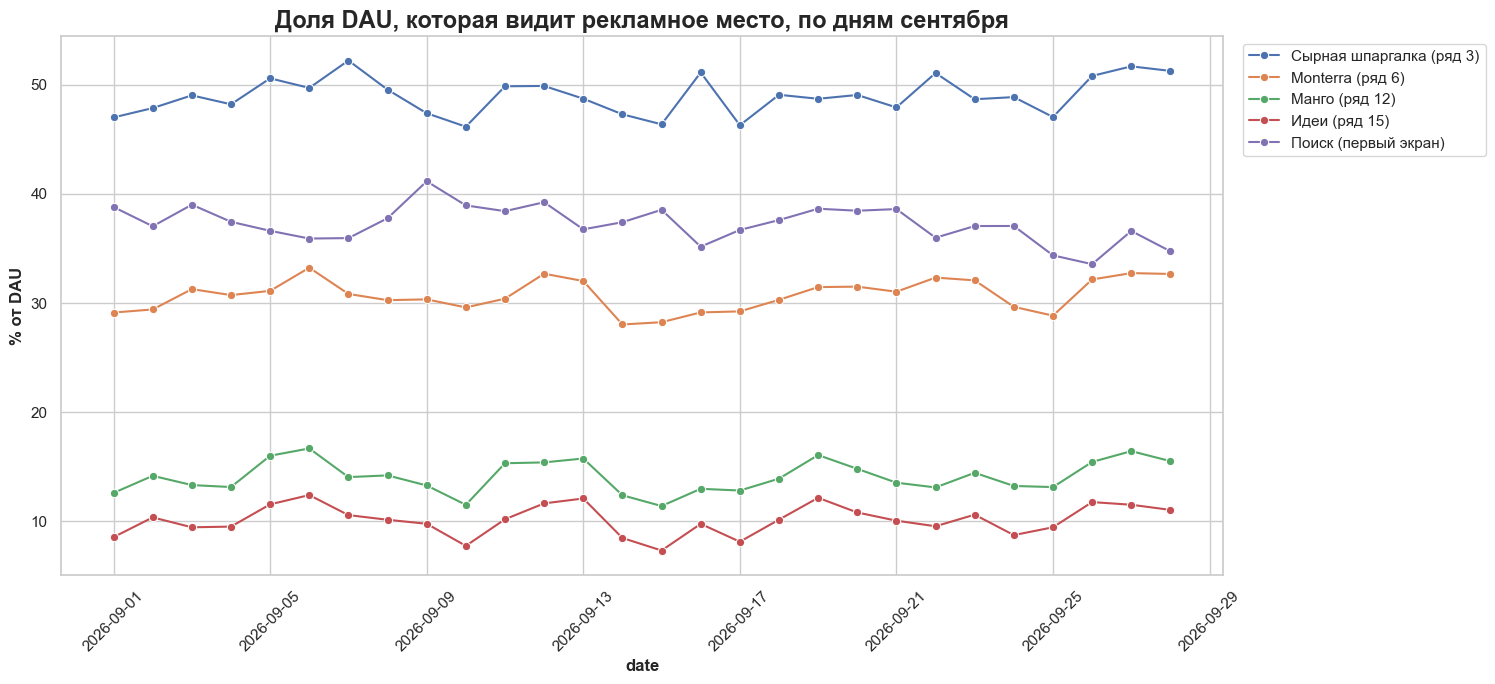

In [15]:
daily_shares = daily[places].div(daily['dau'], axis=0) * 100

plot_shares = daily_shares.reset_index().melt(id_vars='date', var_name='место', value_name='share')

plt.figure(figsize=(15, 7))
sns.lineplot(data=plot_shares, x='date', y='share', hue='место', marker='o')
plt.title('Доля DAU, которая видит рекламное место, по дням сентября', fontsize=17, fontweight='bold')
plt.xlabel('date', fontweight='bold')
plt.ylabel('% от DAU', fontweight='bold')
plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left')

plt.xticks(rotation=45)
plt.show()

In [16]:
daily_shares['week'] = (daily_shares.index.day - 1) // 7 + 1
daily_shares['day_type'] = 'будни'
daily_shares.loc[daily_shares.index.dayofweek >= 5, 'day_type'] = 'выходные'

display(daily_shares.groupby('week')[places].mean().round(1))
print()
print()

display(daily_shares.groupby('day_type')[places].mean().round(1))
print()
print()

print('стандартное отклонение дневной доли, п.п.:')
print(daily_shares[places].std().round(1))

,Сырная шпаргалка (ряд 3),Monterra (ряд 6),Манго (ряд 12),Идеи (ряд 15),Поиск (первый экран)
week,,,,,
1,49.2,30.8,14.3,10.3,37.2
2,48.4,30.5,14.0,10.0,38.5
3,48.3,30.1,13.6,9.7,37.7
4,49.9,31.5,14.4,10.4,35.6


,Сырная шпаргалка (ряд 3),Monterra (ряд 6),Манго (ряд 12),Идеи (ряд 15),Поиск (первый экран)
day_type,,,,,
будни,48.6,30.2,13.4,9.5,37.4
выходные,49.9,32.1,15.8,11.7,36.9




стандартное отклонение дневной доли, п.п.:
Сырная шпаргалка (ряд 3)    1.7
Monterra (ряд 6)            1.5
Манго (ряд 12)              1.5
Идеи (ряд 15)               1.4
Поиск (первый экран)        1.7
dtype: float64


Линии на графике почти ровные, тренда вверх или вниз нет. По неделям доли меняются в пределах 1–3 п.п., стандартное отклонение дневной доли 1,4–1,7 п.п. В выходные до глубоких рядов доходит чуть больше людей (до «Идей» 11,7% против 9,5% в будни), а доля поиска почти не меняется. Ниже проверю, влияет ли это на оценки по месяцам.

### 4.4. Результаты

Представьте оценку среднедневного охвата каждого выбранного места по месяцам — с октября по декабрь. Выберите понятный способ представления результатов и укажите единицы измерения.

In [17]:
months = {'2026-10': 'Октябрь', '2026-11': 'Ноябрь', '2026-12': 'Декабрь'}
forecast = dau.set_index('month')['avg_dau_plan']

result = pd.DataFrame({'доля от DAU, %': (share * 100).round(1)})
for m in months:
    result[months[m]] = (share * forecast[m]).round().astype(int)

result.index.name = 'рекламное место'
result = result.sort_values('доля от DAU, %', ascending=False)

print('план DAU: октябрь', forecast['2026-10'], ', ноябрь', forecast['2026-11'], ', декабрь', forecast['2026-12'])
print('среднедневной охват, уникальных пользователей в день:')
result

план DAU: октябрь 1080.0 , ноябрь 1160.0 , декабрь 1320.0
среднедневной охват, уникальных пользователей в день:


,"доля от DAU, %",Октябрь,Ноябрь,Декабрь
рекламное место,,,,
Сырная шпаргалка (ряд 3),49.0,529,569,647
Поиск (первый экран),37.2,402,432,492
Monterra (ряд 6),30.8,332,357,406
Манго (ряд 12),14.1,153,164,187
Идеи (ряд 15),10.2,110,118,134


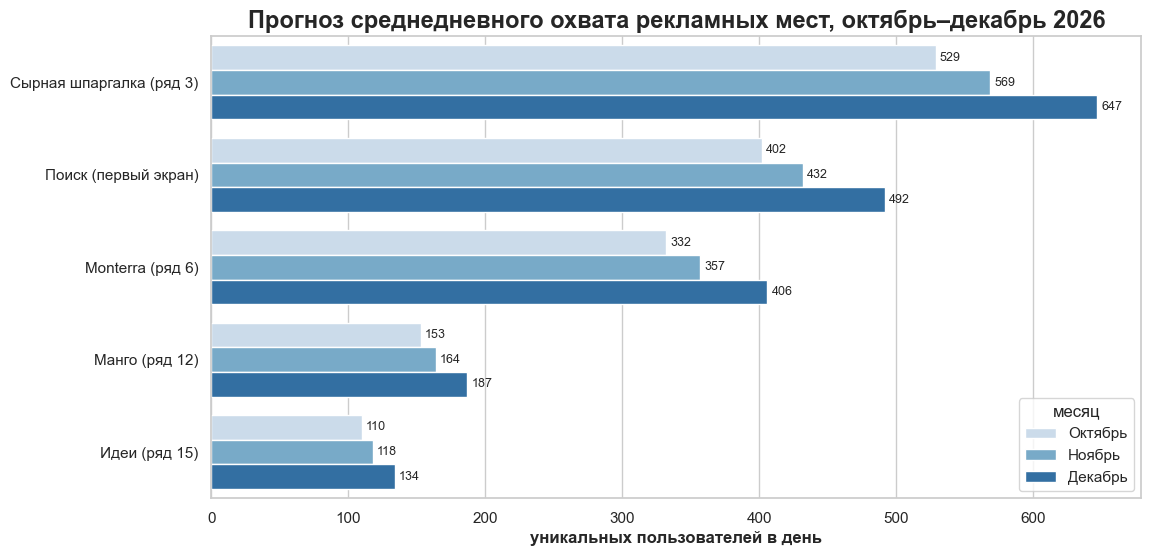

In [18]:
plot_result = result[list(months.values())].reset_index().melt(
    id_vars='рекламное место', var_name='месяц', value_name='охват')

plt.figure(figsize=(12, 6))
ax = sns.barplot(data=plot_result, x='охват', y='рекламное место', hue='месяц', palette='Blues')
for bars in ax.containers:
    ax.bar_label(bars, fontsize=9, padding=3)

plt.title('Прогноз среднедневного охвата рекламных мест, октябрь–декабрь 2026', fontsize=17, fontweight='bold')
plt.xlabel('уникальных пользователей в день', fontweight='bold')
plt.ylabel('')
plt.show()

**Проверка.** В месяцах разное число выходных, а в выходные доли чуть другие. Пересчитаю охват с долями отдельно для будних и выходных и взвешу их по календарю каждого месяца. Ниже разница с основной оценкой (в пользователях):

In [19]:
weekdays = daily[daily.index.dayofweek < 5]
weekends = daily[daily.index.dayofweek >= 5]

share_wd = weekdays[places].mean() / weekdays['dau'].mean()
share_we = weekends[places].mean() / weekends['dau'].mean()

check = pd.DataFrame()
for m in months:
    days = pd.date_range(m + '-01', periods=pd.Period(m).days_in_month)
    n_we = (days.dayofweek >= 5).sum()
    n_wd = len(days) - n_we
    print(months[m], ': будних', n_wd, ', выходных', n_we)

    month_share = (share_wd * n_wd + share_we * n_we) / len(days)
    check[months[m]] = (month_share * forecast[m]).round().astype(int)

print()
print()
(check - result[list(months.values())]).reindex(result.index)

Октябрь : будних 22 , выходных 9
Ноябрь : будних 21 , выходных 9
Декабрь : будних 23 , выходных 8




,Октябрь,Ноябрь,Декабрь
рекламное место,,,
Сырная шпаргалка (ряд 3),0,-1,-1
Поиск (первый экран),0,0,0
Monterra (ряд 6),0,0,-1
Манго (ряд 12),-1,0,-2
Идеи (ряд 15),-1,0,-1


Разница не больше 2 пользователей (около 1%) => календарь месяца на оценку почти не влияет, поэтому оставляю простой вариант.

## 5. Вывод

Ответьте на исследовательский вопрос, опираясь на результаты. Сформулируйте ответ так, чтобы рекламная команда могла использовать его при планировании.

**Ответ рекламной команде:** если реклама показывается всем без таргетинга, то среднедневной охват мест (уникальных пользователей в день) такой:

| Рекламное место | Доля от DAU | Октябрь | Ноябрь | Декабрь |
|---|---|---|---|---|
| «Сырная шпаргалка», лента, ряд 3 | 49,0% | 529 | 569 | 647 |
| Баннер на первом экране поиска | 37,2% | 402 | 432 | 492 |
| Monterra, лента, ряд 6 | 30,8% | 332 | 357 | 406 |
| «Манго», лента, ряд 12 | 14,1% | 153 | 164 | 187 |
| «Идеи», лента, ряд 15 | 10,2% | 110 | 118 | 134 |

**1. самое охватное место — 3 ряд ленты**: его видит примерно половина всех, кто заходит в приложение за день (49% DAU).

**2. баннер в поиске на втором месте** (≈37% DAU) и обгоняет даже Monterra в 6 ряду. Поиск открывает меньше людей, чем ленту (37% vs 71% DAU), но баннер стоит на первом экране и его видит каждый, кто зашёл в поиск, а до 6 ряда ленты долистывают меньше половины пользователей ленты.

**3. чем глубже место в ленте, тем меньше охват**: 6 ряд ≈31% DAU, 12 ≈14%, 15 ≈10%. «Идеи» видит почти в 5 раз меньше людей, чем 3 ряд. Это стоит учитывать в цене размещения, ну или продавать глубокие места пакетом.

**4. охват растёт вместе с DAU**: в декабре он на 22% выше, чем в октябре, тк прогноз DAU растёт с 1080 до 1320.

**5. охваты разных мест нельзя складывать**, тк одни и те же люди видят несколько баннеров (кто долистал до 15 ряда, тот видел и все баннеры выше). И среднедневной охват нельзя умножать на число дней, чтобы получить охват уникальных пользователей за месяц: многие заходят в приложение не один день.

**TO SUM UP**: по охвату места идут так: 3 ряд > поиск > 6 ряд > 12 ряд > 15 ряд. Охват каждого места = его доля от DAU × план DAU на месяц, поэтому если план DAU поменяется, оценку легко пересчитать.

## 6. Ограничения

Что ограничивает применимость ваших оценок? Объясните, как это влияет на интерпретацию и использование результатов.

1) **Поведение взято с сентября.** Я предполагаю, что в октябре–декабре пользователи будут так же часто открывать ленту и поиск и так же глубоко листать ленту. Сильнее всего это может не сработать в декабре: DAU по плану растёт на 14% к ноябрю (новый год, новые пользователи), а новая аудитория и предпраздничные покупки могут поменять глубину просмотра. Поэтому оценку на декабрь стоит считать наименее надёжной.

2) **Прогноз DAU — это план, а не факт.** С января по август факт отличался от плана до ±1,6%, значит и охват может ошибиться примерно на столько же, даже если поведение не изменится.

3) **Это среднее за день, а не охват конкретного дня.** Дневная доля колеблется на 1,4–1,7 п.п., а в выходные до глубоких рядов доходит больше людей (до 15 ряда 11,7% vs 9,5% DAU в будни). Т.е. в отдельные дни охват будет заметно отличаться от среднего.

4) **«Увидел» = «место появилось на экране».** Это потенциальный охват, т.е. верхняя граница: заметил ли человек баннер, по данным понять нельзя. Плюс схема ленты условная, и я предполагаю, что баннер виден тогда же, когда соседняя карточка в его ряду.

5) **Открытия ленты без показов.** В 5,6% случаев пользователь открыл ленту, но не увидел ни одной карточки, и его я не считала увидевшим баннер. Если первый экран у него на самом деле отображался (например, показы просто не записались), охват верхних мест немного занижен.

6) **Баннер в поиске видят все, кто открыл поиск.** Это условие кейса. Если на самом деле часть пользователей попадает сразу в результаты поиска мимо стартового экрана, охват будет ниже.

7) **Без ограничений показа.** Не учтены таргетинг, частотные ограничения и то, что сама реклама может менять поведение (например, глубину прокрутки).

8) Ну и **данные синтетические и всего за 28 дней**, по ним нельзя оценить сезонность.